In [1]:
import pandas as pd
import numpy as np
import xarray as xr
import scipy
import glob
import pathlib
# import dask
# dask.config.set(**{'array.slicing.split_large_chunks': True})
# import sys
import matplotlib.pyplot as plt
import matplotlib as mpl
# import os
# import logging
# import global3d_track as g3d
import string
letters = string.ascii_lowercase
# import tools
# import itertools
# import datetime
# import analytical
# import math
# from IPython.display import HTML

# left = display(HTML("""
# <style>
# .jp-OutputArea-output {
#     display: flex;
#     justify-content: left;
# }
# </style>
# """))

import helpers
import plot_helpers

extra_figs = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_submission/figures/paper_supporting_results')
extra_figs.mkdir(parents=1, exist_ok=1)

In [2]:
# load data

datadir = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_submission/data/statistics_L2')
ds_flist = sorted(list(datadir.glob('*.nc')))
li = []
for i in range(len(ds_flist)):
    ds = xr.open_dataset(ds_flist[i])
    li.append(ds)
ds = xr.concat(li, dim='system')

In [3]:
# filter data

gsystems = ds.max_CMF.dropna('system').system
ds = ds.sel(system=gsystems)
ds = ds.where(ds.category=='isolated').dropna('system', how='all')
print('We have', ds.system.size, 'isolated DCCs')

# ds = ds.where(ds.lifestages_valid).dropna('system', how='all')
# print('Of, these', ds.system.size, 'had all valid lifestages')

We have 4487 isolated DCCs


In [4]:
# calculate intensity quartiles

intensity_measures = ['total_CMT','max_CMT','max_CMF','max_w','max_Ac','conv_lifetime']
df_metrics = helpers.dccs_by_intensity_metrics(ds, ds[intensity_measures])

# define a global colormap
CMAP = mpl.colors.ListedColormap(plt.get_cmap('Reds')(np.linspace(.25,1,265)))

# choose output format
dpi = 300
ext = 'pdf'

#### LIFESTAGE DETAILS
Assess the typicaly lifestage durations of the DCCs.

NameError: name 'extradir' is not defined

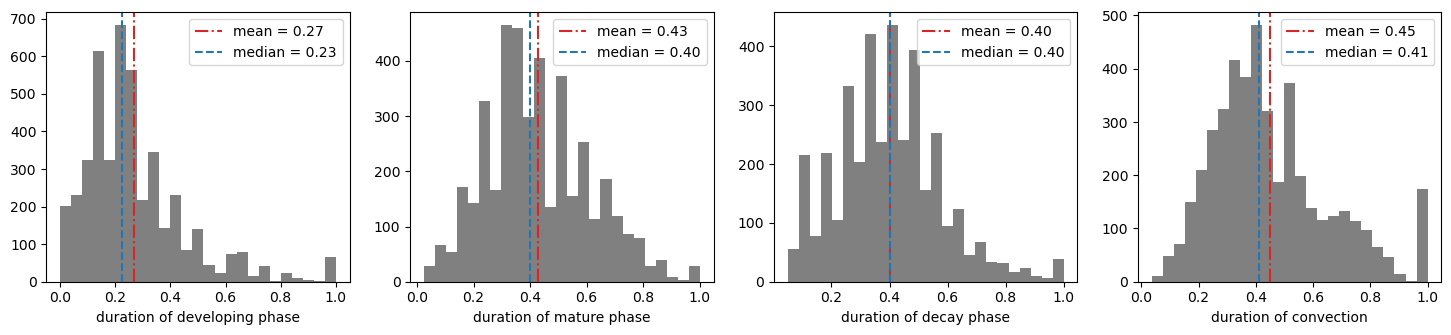

In [5]:
fig, axs = plt.subplots(1,4, figsize=(18, 3.5))

params = dict(fc="grey", bins=25)

plots = [
    (ds.t_max_depth, "duration of developing phase"),
    ((ds.t_max_area - ds.t_max_depth).where(lambda x: x > 0), "duration of mature phase"),
    ((1 - ds.t_max_area).where(lambda x: x > 0), "duration of decay phase"),
    (ds.conv_lifetime / ds.lifetime, "duration of convection"),
]

for ax, (d, xlabel) in zip(axs, plots):
    d.plot.hist(ax=ax, **params)

    mean = d.mean()
    median = d.median()

    ax.axvline(mean, c="tab:red", ls="-.", label=f"mean = {mean.item():.2f}")
    ax.axvline(median, c="tab:blue", ls="--", label=f"median = {median.item():.2f}")

    ax.set_xlabel(xlabel)
    ax.legend()

fig.savefig(extra_figs / f'lifestage_durations.{ext}', bbox_inches='tight', dpi=dpi)

#### CALCULATING Mc QUARTILES
Assess the derived quartiles of the DCC total convective mass flux at the anvil base height

In [ ]:
# data
land = ds.sel(system=ds.system.where(ds.ocean_fraction < 0.5, drop=True))
ocean = ds.sel(system=ds.system.where(ds.ocean_fraction >= 0.5, drop=True))

fig, ax = plt.subplots(figsize=(8,4), layout="tight")
hist_params = dict(bins=40, density=True, histtype="stepfilled", alpha=1, fc="none", ec="k")

# histograms
land.total_CMT.plot.hist(ax=ax, lw=2, label="Land", **hist_params,)
ocean.total_CMT.plot.hist(ax=ax, lw=1, label="Ocean", **hist_params,)

# quantiles
quantiles = ds.total_CMT.quantile([0, 0.25, 0.5, 0.75, 1]).rename({"quantile":"pi"})

for i, q in enumerate(quantiles.pi.values):
    ax.axvline(
        quantiles.sel(pi=q),
        color=CMAP(i / (len(quantiles) - 1)),
        lw=1.5,
        label=f"{int(100 * q)}th percentile",
    )

ax.set_xlabel("Total $M_c$ [kg]")
ax.set_ylabel("Density")
ax.legend(frameon=False)

fig.savefig(extra_figs / f'total_Mc_quartiles.{ext}', bbox_inches='tight', dpi=dpi)

#### CLOUD RESPONSE OF RELATED VARIABLES
Assess the cloud response to total convective mass flux for two related variables, total anvil condensate and anvil horizontal divergence

In [ ]:
# data
cloud_variables = ["anvil_tw", "anvil_div_max"]

# mean evolution by percentile bin
pdata = helpers.group_dataset_by_intensity(ds[cloud_variables], df_metrics, apply=lambda x: x.mean("system", keep_attrs=True),)["total_CMT"]

# figure
N = len(cloud_variables)
fig, axs = plt.subplots(1,N, figsize=(N * 4.5, 3.75), layout="tight")
axs = np.atleast_1d(axs)

legend_handles, legend_labels = None, None

for i, var in enumerate(cloud_variables):
    ax = axs[i]

    for j, b in enumerate(pdata.bins.values):
        color = CMAP(j / 4 + 0.1)
        evolution = plot_helpers.get_evolution(pdata[var].sel(bins=b))
        evolution.plot(ax=ax, c=color, label=f"{b}th", zorder=1, lw=1.5)

    plot_helpers.show_phases(ax, y=ax.get_ylim()[1] * 0.05)

    ax.text(
        0.015,
        0.9,
        f"({letters[i]}) {ds[var].long_name.capitalize()}",
        c="k",
        weight="bold",
        transform=ax.transAxes,
    )

    ax.set_xlabel("Normalised lifetime")
    ax.set_ylabel(f"{ds[var].long_name.replace('anvil', '').capitalize()} [{ds[var].units}]")
    ax.set_title(None)

    ax.set_ylim(0, ax.get_ylim()[1] * 1.2)

    if legend_handles is None:
        legend_handles, legend_labels = ax.get_legend_handles_labels()

legend = fig.legend(
    legend_handles,
    legend_labels,
    title=r"$\int M_c dt$ percentile",
    loc="center",
    bbox_to_anchor=(0.5, -0.1),
    ncol=4,
    frameon=True,
)

fig.savefig(extra_figs / f'cloud_response_water_and_wind.{ext}', bbox_inches='tight', dpi=dpi)

#### PREDICTIVE SKILL
Assess predictive skill of the two area prediction models

In [ ]:
# skill comparison

# model_names = ("Apred_v1_conv", "Apred_v3_conv")
# model_equations = {
#                    'Apred_v1_conv':r'$\frac{1}{D\bar{\rho}}\int M_{c,max}\,dt$',
#                    'Apred_v3_conv':r'$\int \frac{M_c}{D\bar{\rho}}\,dt$'
#                 }

model_names = ("Apred_v1", "Apred_v2")
model_equations = {
                   'Apred_v1':r'$\frac{1}{D\bar{\rho}}\int M_{c,max}\,dt$',
                   'Apred_v2':r'$\int \frac{M_c}{D\bar{\rho}}\,dt$',
                }


fig, axs = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")

extent = (0, 4e10, 0, 4e10)
max_extent = extent[1]
hexbin_params = dict(gridsize=40, mincnt=1, reduce_C_function=np.sum, extent=extent,)
tparams = dict(c='k', weight='bold', va='top')

hcmap = mpl.colors.ListedColormap(plt.get_cmap("cividis")(np.linspace(0.25, 1, 256)))
norm = mpl.colors.Normalize(vmin=0, vmax=250)

for i, model in enumerate(model_names):
    ax = axs[i]

    true = ds.cloud_area.max("interp_time")
    pred = ds[model].max("interp_time")

    x, y, xline, yline, slope, rscore = helpers.evaluate_predictions(true, pred)

    hb = ax.hexbin(x, y, C=np.ones_like(x), cmap=hcmap, norm=norm, **hexbin_params,)
    ax.plot([0, max_extent], [0, max_extent], c="k", ls=":", label="1:1")

    mask = (xline <= max_extent) & (yline <= max_extent)
    ax.plot(xline[mask], yline[mask], c="darkblue", ls="-.",label=rf"$r$ = {rscore:.2f}",)

    ax.set_xlabel("Maximum area [m$^2$]")
    ax.set_ylabel("Predicted maximum area [m$^2$]")
    ax.legend(frameon=True, loc="lower right")

    ax.text(
        0.015,
        0.95,
        f"({letters[i]}) {model_equations[model]}",
        transform=ax.transAxes,
        **tparams,
    )
    ax.set_title(None)

cbar = fig.colorbar(hb, ax=axs, location="right", fraction=0.05)
cbar.ax.set_title("Counts")

fig.savefig(extra_figs / f'model_skill.{ext}', bbox_inches='tight', dpi=dpi)